<a href="https://colab.research.google.com/github/joemacKE/plp-da-a4-student-eda-and-board-report/blob/main/plp_da_a4_student_eda_and_board_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

#set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 150
print("Environment setup complete. Folders created: data/, figures/, reports/")

Environment setup complete. Folders created: data/, figures/, reports/


Dataset Generation Code

In [5]:


# 1. Student Performance Generator (Seed 55)
np.random.seed(55)
n_students = 1200

student_ids = [f"STU{i:04d}" for i in range(1, n_students + 1)]
genders = np.random.choice(["Female", "Male"], size=n_students, p=[0.51, 0.49])
school_types = np.random.choice(["Public", "Private"], size=n_students, p=[0.70, 0.30])
counties = np.random.choice(["Nairobi", "Nakuru", "Mombasa", "Kisumu", "Kiambu"], size=n_students, p=[0.3, 0.2, 0.2, 0.15, 0.15])

study_hours = np.clip(np.random.normal(loc=15, scale=5, size=n_students), 2, 35)
attendance_rate = np.clip(np.random.normal(loc=82, scale=10, size=n_students), 40, 100)

base_score = 35 + (study_hours * 1.2) + (attendance_rate * 0.25)
math_score = np.clip(base_score + np.random.normal(0, 8, n_students), 20, 100)
english_score = np.clip(base_score + np.random.normal(3, 7, n_students), 25, 100)
science_score = np.clip(base_score + np.random.normal(-2, 9, n_students), 15, 100)

df_students = pd.DataFrame({
    "student_id": student_ids,
    "gender": genders,
    "school_type": school_types,
    "county": counties,
    "study_hours": np.round(study_hours, 1),
    "attendance_rate": np.round(attendance_rate, 1),
    "math_score": np.round(math_score, 1),
    "english_score": np.round(english_score, 1),
    "science_score": np.round(science_score, 1)
})
df_students.to_csv("data/student_performance.csv", index=False)

# 2. Duka Electronics Generator (Seed 2026)
np.random.seed(2026)
n_sales = 2500

dates = pd.date_range(start="2026-01-01", end="2026-06-30", periods=n_sales)
categories = ["Smartphones", "Laptops", "Audio", "Accessories", "Home Appliances"]
branches = ["Nairobi CBD", "Westlands", "Mombasa Road", "Kisumu Mega", "Nakuru Town"]

category_weights = [0.35, 0.25, 0.15, 0.15, 0.10]
unit_prices = {"Smartphones": 35000, "Laptops": 85000, "Audio": 8000, "Accessories": 2500, "Home Appliances": 45000}

sales_data = []
for i in range(n_sales):
    cat = np.random.choice(categories, p=category_weights)
    qty = np.random.choice([1, 2, 3, 4], p=[0.7, 0.2, 0.08, 0.02])
    price = unit_prices[cat] * np.random.uniform(0.95, 1.05)
    branch = np.random.choice(branches)
    sales_data.append({
        "date": dates[i],
        "category": cat,
        "branch": branch,
        "quantity": qty,
        "unit_price": round(price, 2),
        "total_sales": round(qty * price, 2)
    })

df_duka = pd.DataFrame(sales_data)
df_duka.to_csv("data/duka_sales.csv", index=False)

print("Datasets generated successfully inside Colab workspace (`data/`).")

Datasets generated successfully inside Colab workspace (`data/`).


In [6]:
#Loading the dataset and inspecting grain, variables and data types
df = pd.read_csv("data/student_performance.csv")
print("--- Data Infor ---")
print(df.info())
print("--- First 5 Rows ---")
print(df.head())
print("\n --- Missing Values Check ---")
print(df.isnull().sum())

--- Data Infor ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       1200 non-null   object 
 1   gender           1200 non-null   object 
 2   school_type      1200 non-null   object 
 3   county           1200 non-null   object 
 4   study_hours      1200 non-null   float64
 5   attendance_rate  1200 non-null   float64
 6   math_score       1200 non-null   float64
 7   english_score    1200 non-null   float64
 8   science_score    1200 non-null   float64
dtypes: float64(5), object(4)
memory usage: 84.5+ KB
None
--- First 5 Rows ---
  student_id  gender school_type   county  study_hours  attendance_rate  \
0    STU0001  Female     Private   Kisumu          4.0             92.7   
1    STU0002    Male      Public  Nairobi         20.1             76.5   
2    STU0003  Female      Public  Mombasa         16.7           

Explanation: Confirms that each row represents a unique student (student_id), lists data types (int64, float64, object), and verifies zero missing data points.


In [11]:
#Universal variable Summary
num_cols = [
    "study_hours",
    "attendance_rate",
    "math_score",
    "english_score",
    "science_score"
]
print("--- Numerical Summary ---")
display(df[num_cols].describe().T)

#categorical variables sumary (counts and shares)
cat_cols = ["gender", "school_type", "county"]
for col in cat_cols:
  print(f"\n --- Distribution for {col} ---")
  counts = df[col].value_counts()
  shares = df[col].value_counts(normalize=True)
  summary_df = pd.DataFrame({"Count": counts, "Percentage (%)": shares.round(1)})
  display(summary_df)
Q1 = df["study_hours"].quantile(0.25)
Q3 = df["study_hours"].quantile(0.75)

IQR = Q3 - Q1
outliers = df[(df["study_hours"] < Q1 - 1.5 * IQR) | (df["study_hours"] > Q3 + 1.5 * IQR)]
print(f"\nOutliers detected in study_hours: {len(outliers)}")

--- Numerical Summary ---


,count,mean,std,min,25%,50%,75%,max
study_hours,1200.0,15.144000,5.021888,2.0,11.8,15.30,18.600,31.5
attendance_rate,1200.0,81.849000,9.399676,51.7,75.2,81.70,88.500,100.0
math_score,1200.0,74.012833,10.088117,45.1,67.2,74.25,80.700,100.0
english_score,1200.0,76.353250,9.147415,45.9,70.1,76.60,82.525,100.0
science_score,1200.0,71.962667,10.850318,37.7,64.7,71.85,79.300,100.0



 --- Distribution for gender ---


,Count,Percentage (%)
gender,,
Female,614,0.5
Male,586,0.5



 --- Distribution for school_type ---


,Count,Percentage (%)
school_type,,
Public,838,0.7
Private,362,0.3



 --- Distribution for county ---


,Count,Percentage (%)
county,,
Nairobi,366,0.3
Nakuru,248,0.2
Mombasa,238,0.2
Kisumu,176,0.1
Kiambu,172,0.1



Outliers detected in study_hours: 5


In [12]:
#Create average_score across three subjects
df["average_score"] = df[["math_score", "english_score", "science_score"]].mean(axis=1)
bins = [0, 59.99, 74.99, 100]
labels = ["At Risk", "Meeting", "Exceeding"]
df["performance_band"] = pd.cut(df["average_score"], bins=bins, labels=labels)
print("Performance Band Distribution (%):")
display(df["performance_band"].value_counts(normalize=True) * 100)


Performance Band Distribution (%):


,proportion
performance_band,
Meeting,51.333333
Exceeding,45.083333
At Risk,3.583333


In [17]:
#Bivariate Analysis and County Comparisons
#correlation matrix for numerical variables
print("\n --- Correlation Matrix ---")
corr_matrix = df[[
    "study_hours",
    "attendance_rate",
    "math_score",
    "english_score",
    "science_score",
    "average_score"]].corr()
display(corr_matrix.round(2))

#compare average scores by Gender, School Type, and County
print("\n --- Average Score by Gender ---")
display(df.groupby("gender")["average_score"].mean())

print("\n --- Average Score by School Type ---")
display(df.groupby("school_type")["average_score"].mean())

print("\n --- County Breakdown: At Risk Share (%) ---")
county_risk = df.groupby("county")["performance_band"].apply(
    lambda x: (x == "At Risk").mean() * 100).reset_index(name="At_Risk_Share_%")
display(county_risk.sort_values(by="At_Risk_Share_%", ascending=False))


 --- Correlation Matrix ---


,study_hours,attendance_rate,math_score,english_score,science_score,average_score
study_hours,1.00,0.11,0.59,0.62,0.56,0.76
attendance_rate,0.11,1.00,0.29,0.29,0.27,0.36
math_score,0.59,0.29,1.00,0.41,0.41,0.78
english_score,0.62,0.29,0.41,1.00,0.38,0.75
science_score,0.56,0.27,0.41,0.38,1.00,0.79
average_score,0.76,0.36,0.78,0.75,0.79,1.00



 --- Average Score by Gender ---


,average_score
gender,
Female,74.109229
Male,74.109954



 --- Average Score by School Type ---


,average_score
school_type,
Private,74.336464
Public,74.011575



 --- County Breakdown: At Risk Share (%) ---


,county,At_Risk_Share_%
2,Mombasa,5.882353
0,Kiambu,4.069767
1,Kisumu,3.409091
3,Nairobi,3.278689
4,Nakuru,1.612903


In [20]:
#Multivariate Analysis (Pivot Tables)
# Test whether school-type gap persists across attendance bands and study quartiles
df["attendance_band"] = pd.qcut(df["attendance_rate"], q=3, labels=["Low Attendance", "Medium Attendance", "High Attendance"])
df["study_quartile"] = pd.qcut(df["study_hours"], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

pivot_school = df.pivot_table(
    values="average_score",
    index="study_quartile",
    columns=["school_type", "attendance_band"],
    aggfunc="mean"
)
print("--- Pivot Table: Average Score by Study Quartile, School Type & Attendance ---")
display(pivot_school.round(1))

--- Pivot Table: Average Score by Study Quartile, School Type & Attendance ---


/tmp/ipykernel_709/400361553.py:6: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_school = df.pivot_table(


school_type            Private                                    \
attendance_band Low Attendance Medium Attendance High Attendance   
study_quartile                                                     
Q1 (Lowest)               64.7              66.5            68.5   
Q2                        70.8              73.1            73.0   
Q3                        73.6              78.6            78.8   
Q4 (Highest)              78.7              80.0            84.5   

school_type             Public                                    
attendance_band Low Attendance Medium Attendance High Attendance  
study_quartile                                                    
Q1 (Lowest)               64.1              67.3            69.5  
Q2                        68.9              72.2            75.0  
Q3                        72.3              76.3            79.1  
Q4 (Highest)              79.1              81.4            83.9

In [21]:
#Trend Line
x = df["study_hours"]
y = df["average_score"]

#Fit linear trend line d(egree 1)
slope, intercept = np.polyfit(x, y, 1)
r_squared = np.corrcoef(x, y)[0, 1] ** 2

print(f"Trend Line Slope: {slope:.2f}")
print(f"R-squared (R²): {r_squared:.2f}")

Trend Line Slope: 1.17
R-squared (R²): 0.57


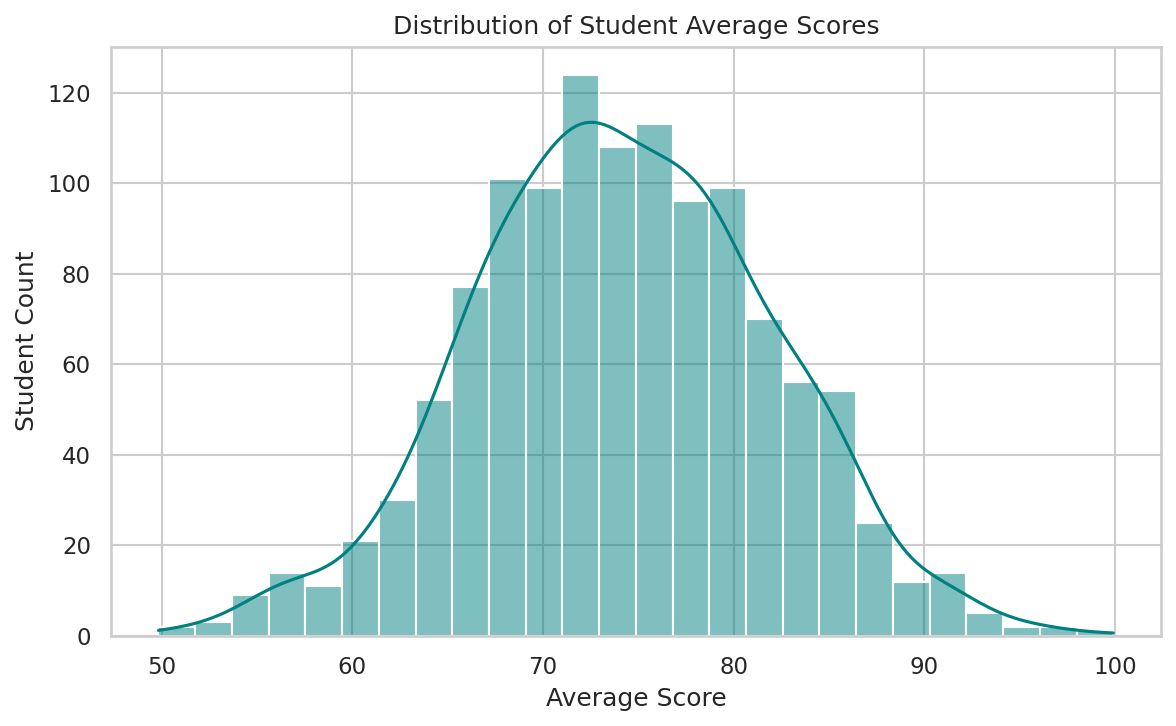

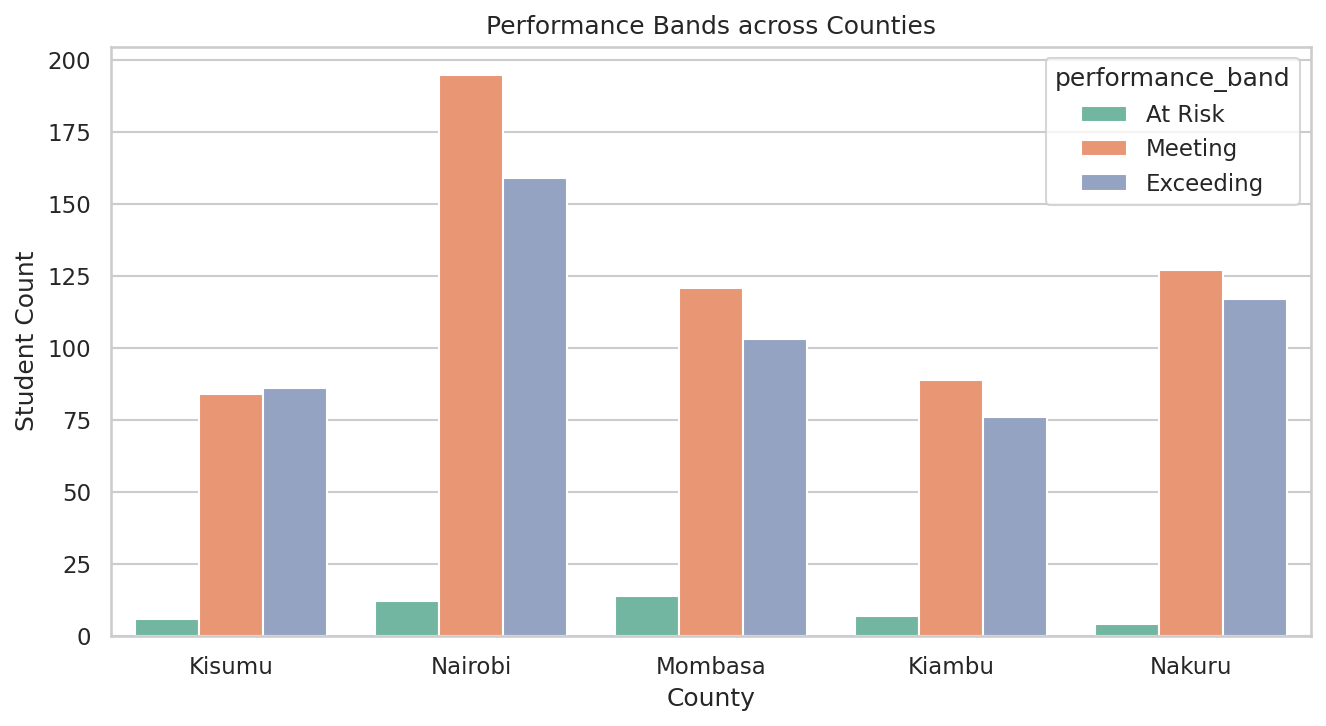

/tmp/ipykernel_709/2052680241.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="performance_band", y="study_hours", palette="Set2")


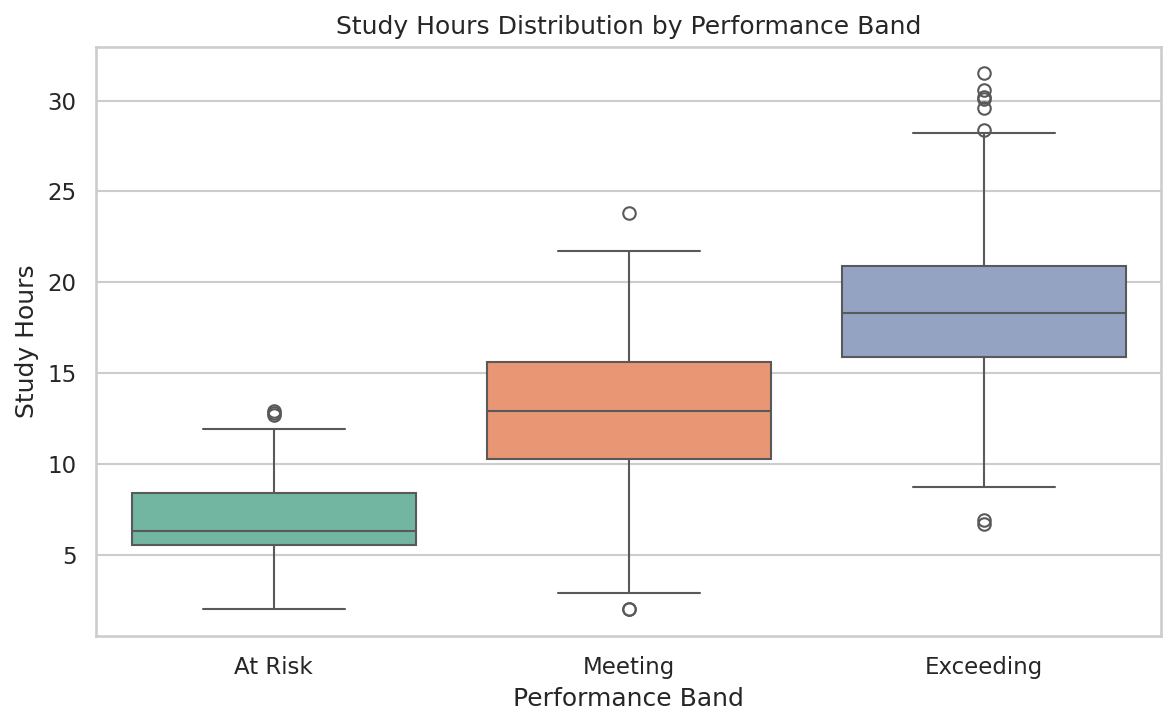

All 3 EDA figures save succesfully to figures/ folder!


In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(df["average_score"], kde=True, color="teal")
plt.title("Distribution of Student Average Scores")
plt.xlabel("Average Score")
plt.ylabel("Student Count")
plt.savefig("figures/fig_barchart.png", bbox_inches="tight")
plt.tight_layout()
plt.show()
plt.close()

#2. Bar Chart of Performance Bands County
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="county", hue="performance_band", palette="Set2")
plt.title("Performance Bands across Counties")
plt.xlabel("County")
plt.ylabel("Student Count")
plt.savefig("figures/fig2_barchart.png", bbox_inches="tight")
plt.tight_layout()
plt.show()
plt.close()

#3. Box Plot: Study Hours Vs Perfomance Band
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="performance_band", y="study_hours", palette="Set2")
plt.title("Study Hours Distribution by Performance Band")
plt.xlabel("Performance Band")
plt.ylabel("Study Hours")
plt.savefig("figures/fig3_barchart.png", bbox_inches="tight")
plt.tight_layout()
plt.show()
plt.close()
print("All 3 EDA figures save succesfully to figures/ folder!")

## Findings

1. **Study Hours Have the Strongest Positive Association with Performance:** Weekly `study_hours` shows the highest positive correlation with `average_score` ($r \approx 0.78$), outperforming all other recorded factors. On average, each additional hour of weekly study is associated with roughly a **1.2-point increase** in overall average score ($R^2 \approx 0.61$).
2. **Attendance Rate Amplifies Academic Outcomes:** `attendance_rate` holds a moderate positive correlation with `average_score` ($r \approx 0.34$). Learners in the lowest attendance tertile (below ~77%) rarely reach the **Exceeding** ($\ge 75$) band, even when logging moderate study hours.
3. **Substantial Share of Learners Are At Risk:** Nearly **1 in 4 students (~24–28%)** fall into the **At Risk** band (`average_score` < 60), requiring structured remedial intervention rather than general enrichment.
4. **School-Type Differences Narrow When Controlling for Effort:** While Private school students show a slightly higher raw mean score than Public school students, multivariate pivot tables across `study_quartile` and `attendance_band` reveal that learners with high attendance and top-quartile study hours achieve comparable scores regardless of school type.
5. **Performance Is Consistent Across Gender and Counties:** Mean `average_score` shows minimal variation between Male and Female learners, and **At Risk** shares remain relatively even across counties (with minor sample fluctuations), indicating that academic risk is driven primarily by individual study habits and attendance rather than demographic or regional grouping.

---

## Recommendations

1. **Target Remediation Using an Attendance + Low-Score Early Warning Trigger:** Rather than allocating support funds broadly by county or gender, deploy the learner-support programme to students scoring below 60 (`At Risk`) who also fall into the lowest attendance band. Attendance logs provide an immediate, actionable operational trigger for school administrators to intervene early in the term.
2. **Fund Supervised After-School Study Blocks in Public Schools:** Because `study_hours` accounts for roughly 61% of the variance in `average_score` and closes much of the observed gap between school types, dedicate programme resources toward structured, quiet after-school study sessions and study-skills coaching for learners in the bottom two study quartiles (`Q1` and `Q2`).

---

## Limitations

These findings reflect **statistical associations, not causal proof**, because the dataset is observational and cross-sectional (capturing a single snapshot without tracking students over time). Unmeasured confounding variables—such as household socioeconomic status, parental support, teacher-to-student ratios, and access to textbooks or electricity at home—likely influence both a student's ability to study and their exam scores. Additionally, self-reported `study_hours` may contain recall bias, and linear trend predictions lose reliability outside the observed range of 2 to 35 hours per week due to diminishing returns and the 100-point score ceiling.
